# Entrega 2 — Baseline (TF-IDF + LR) vs. BETO fine-tuneado

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MathiasVeraM/proyecto-semestral-ia2/blob/main/notebooks/01_baseline_vs_beto.ipynb)

Clasificación de observaciones de un centro de rescate animal en 0 (Normal), 1 (Riesgo Leve), 2 (Riesgo Alto).

**Protocolo:** mismos splits estratificados 70/15/15 para todos los modelos; hiperparámetros elegidos solo con
*validación*; el *test* se evalúa una vez al final. Métricas: F1 ponderado (principal), F1 macro, recall de la clase 2
y latencia por observación.

> En Colab: Entorno de ejecución → Cambiar tipo de entorno → **GPU (T4)** antes de ejecutar la sección de BETO.

## 0. Configuración del entorno

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MathiasVeraM/proyecto-semestral-ia2.git"

if IN_COLAB:
    if not os.path.exists("proyecto-semestral-ia2"):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("proyecto-semestral-ia2")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "accelerate"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # ejecución local: subir a la raíz del repo
sys.path.insert(0, os.getcwd())
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/proyecto-semestral-ia2


In [2]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.config import DATA_RAW, SEED, LABELS
from src.baseline import make_majority, make_tfidf_lr, select_C
from src.evaluate import compute_metrics, report_text, plot_confusion, measure_latency
from src.train_beto import BetoConfig, train_beto, predict, make_predict_one, get_device, set_seed

pd.set_option("display.max_colwidth", 110)
COL = {"mayoritaria": "#9aa0a6", "tfidf": "#4c78a8", "beto": "#e07b39"}
Path("results/figures").mkdir(parents=True, exist_ok=True)
Path("results/tables").mkdir(parents=True, exist_ok=True)
print("Dispositivo:", get_device(), "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Datos y preprocesamiento

In [3]:
# Si no existen los splits, se generan (dataset sintético -> limpieza -> split 70/15/15)
if not DATA_RAW.exists():
    subprocess.run([sys.executable, "-m", "src.generate_dataset"], check=True)
if not Path("data/processed/train.csv").exists():
    subprocess.run([sys.executable, "-m", "src.preprocess"], check=True)

train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test = pd.read_csv("data/processed/test.csv")
print(json.dumps(json.load(open("data/processed/preprocess_report.json", encoding="utf-8")), indent=2, ensure_ascii=False))

{
  "filas_iniciales": 691,
  "descartadas_nulas": 2,
  "descartadas_vacias_tras_limpieza": 2,
  "descartadas_muy_cortas": 4,
  "descartadas_etiqueta_invalida": 0,
  "descartadas_etiquetas_contradictorias": 0,
  "descartadas_duplicadas": 8,
  "filas_finales": 675,
  "distribucion_clases": {
    "0": 305,
    "1": 213,
    "2": 157
  },
  "train_tamano": 472,
  "train_clases": {
    "0": 213,
    "1": 149,
    "2": 110
  },
  "val_tamano": 101,
  "val_clases": {
    "0": 46,
    "1": 32,
    "2": 23
  },
  "test_tamano": 102,
  "test_clases": {
    "0": 46,
    "1": 32,
    "2": 24
  },
  "semilla": 42
}


,train,val,test
Normal,213,46,46
Riesgo Leve,149,32,32
Riesgo Alto,110,23,24


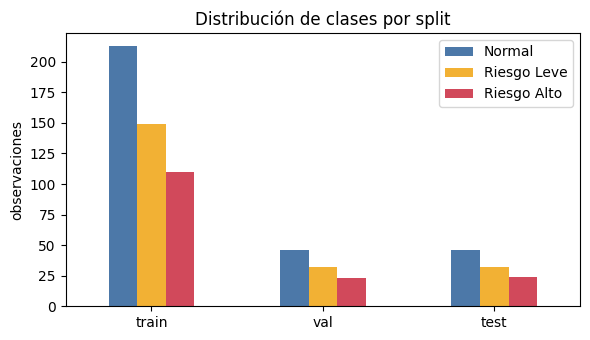

In [4]:
# Distribución de clases por split
dist = pd.DataFrame({n: d["etiqueta"].value_counts().sort_index() for n, d in
                     [("train", train), ("val", val), ("test", test)]})
dist.index = [LABELS[i] for i in dist.index]
display(dist)
ax = dist.T.plot(kind="bar", figsize=(6, 3.5), color=["#4c78a8", "#f2b134", "#d1495b"], rot=0)
ax.set_ylabel("observaciones"); ax.set_title("Distribución de clases por split")
plt.tight_layout(); plt.savefig("results/figures/distribucion_clases.png", dpi=150); plt.show()

In [5]:
# Efecto del preprocesamiento (texto original -> limpio)
display(train[["texto_original", "texto", "etiqueta"]].sample(8, random_state=1))

,texto_original,texto,etiqueta
179,sangra por la boca y no puede tragar,sangra por la boca y no puede tragar,2
298,"Ya en el recinto Rufo cojea ligeramente de la pata trasera, pero camina Voluntario de turno: Pedro..","ya en el recinto rufo cojea ligeramente de la pata trasera, pero camina voluntario de turno: pedro.",1
31,"Tras la sesión de enriquecimiento Pancho no hubo vómitos, no hay sangrado y respira normal 😅","tras la sesión de enriquecimiento pancho no hubo vómitos, no hay sangrado y respira normal",0
453,"temblores y rigidez en todo el cuerpo, no reacciona","temblores y rigidez en todo el cuerpo, no reacciona",2
247,pasó de decaído a inconsciente en menos de una hora,pasó de decaído a inconsciente en menos de una hora,2
245,"La perra Moka no puede levantarse, arrastra las patas traseras Anotado por el turno de la tarde. 😊","la perra moka no puede levantarse, arrastra las patas traseras anotado por el turno de la tarde.",2
172,"frida (gata) no se observa decaimiento, está alerta y curiosa sin mas comentarios.","frida (gata) no se observa decaimiento, está alerta y curiosa sin mas comentarios.",0
295,"Sobre Luna: descartamos convulsiones, todo tranquilo durante el turno Clima soleado.","sobre luna: descartamos convulsiones, todo tranquilo durante el turno clima soleado.",0


## 2. Baselines

- **Clase mayoritaria:** piso de referencia; muestra lo engañosa que es la *accuracy* con clases desbalanceadas.
- **TF-IDF + Regresión Logística:** bolsa de palabras ponderada (unigramas y bigramas). No modela orden ni negación.
  El hiperparámetro `C` se elige por F1 ponderado en validación. Se entrena solo con *train* (igual que BETO).

In [6]:
rows = []   # resultados de todos los modelos
preds = {}  # predicciones de test para el análisis de errores

def registrar(nombre, y_val, p_val, y_test, p_test, extra=None):
    for split, y, p in (("val", y_val, p_val), ("test", y_test, p_test)):
        rows.append({"modelo": nombre, "split": split, **compute_metrics(y, p), **(extra or {})})
    preds[nombre] = np.asarray(p_test)

X_tr, y_tr = train["texto"], train["etiqueta"]
X_va, y_va = val["texto"], val["etiqueta"]
X_te, y_te = test["texto"], test["etiqueta"]

# 1) Clase mayoritaria
maj = make_majority().fit(X_tr, y_tr)
registrar("Mayoritaria", y_va, maj.predict(X_va), y_te, maj.predict(X_te))

# 2) TF-IDF + LR (sin pesos de clase) y 3) con pesos balanceados
tfidf_models = {}
for nombre, cw in (("TF-IDF + LR", None), ("TF-IDF + LR (balanceado)", "balanced")):
    C, tabla = select_C(X_tr, y_tr, X_va, y_va, class_weight=cw)
    print(f"{nombre}: F1 val por C = { {k: round(v, 3) for k, v in tabla.items()} } -> C = {C}")
    m = make_tfidf_lr(C, cw).fit(X_tr, y_tr)
    tfidf_models[nombre] = m
    registrar(nombre, y_va, m.predict(X_va), y_te, m.predict(X_te), {"C": C})

TF-IDF + LR: F1 val por C = {0.1: 0.346, 1: 0.871, 10: 0.901, 100: 0.901} -> C = 10
TF-IDF + LR (balanceado): F1 val por C = {0.1: 0.843, 1: 0.901, 10: 0.902, 100: 0.912} -> C = 100


,modelo,split,accuracy,f1_weighted,f1_macro,recall_clase0,recall_clase1,recall_clase2,C
0,Mayoritaria,val,0.455,0.285,0.209,1.000,0.000,0.000,NaN
1,Mayoritaria,test,0.451,0.280,0.207,1.000,0.000,0.000,NaN
2,TF-IDF + LR,val,0.901,0.901,0.893,0.957,0.875,0.826,10.0
3,TF-IDF + LR,test,0.892,0.892,0.880,0.957,0.875,0.792,10.0
4,TF-IDF + LR (balanceado),val,0.911,0.912,0.894,0.957,0.906,0.826,100.0
5,TF-IDF + LR (balanceado),test,0.892,0.893,0.877,0.935,0.906,0.792,100.0


              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95        46
 Riesgo Leve       0.82      0.88      0.85        32
 Riesgo Alto       0.90      0.79      0.84        24

    accuracy                           0.89       102
   macro avg       0.89      0.87      0.88       102
weighted avg       0.89      0.89      0.89       102



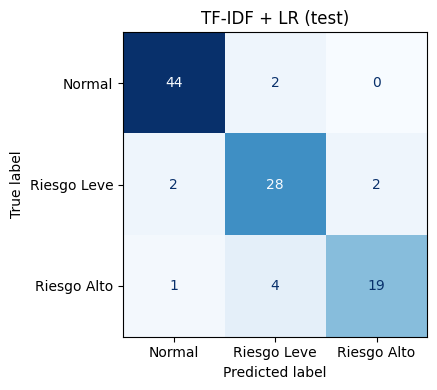

In [7]:
res = pd.DataFrame(rows)
display(res[res.modelo != "BETO"].round(3))
print(report_text(y_te, preds["TF-IDF + LR"]))
fig, ax = plt.subplots(figsize=(4.8, 4))
plot_confusion(y_te, preds["TF-IDF + LR"], "TF-IDF + LR (test)", ax)
plt.tight_layout(); plt.savefig("results/figures/cm_tfidf.png", dpi=150); plt.show()

## 3. BETO fine-tuneado (versión inicial)

`dccuchile/bert-base-spanish-wwm-cased` + cabeza de clasificación lineal (3 clases). Configuración **intencionalmente
simple**: sin pérdida ponderada, sin congelar capas, sin búsqueda de hiperparámetros. Se conserva la época con
mejor F1 en validación. Las mejoras (Weighted Cross-Entropy, búsqueda de lr/épocas, DistilBETO, cuantización/ONNX)
quedan para la entrega final.

In [8]:
cfg = BetoConfig()
print(json.dumps(cfg.to_dict(), indent=2))
model, tok, hist = train_beto(train, val, cfg)
hist = pd.DataFrame(hist); display(hist.round(4))

{
  "model_name": "dccuchile/bert-base-spanish-wwm-cased",
  "max_len": 96,
  "batch_size": 16,
  "lr": 2e-05,
  "weight_decay": 0.01,
  "epochs": 5,
  "warmup_ratio": 0.1,
  "seed": 42,
  "use_class_weights": false
}


config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

época 1/5  train_loss=1.0297  val_loss=0.8046  val_f1=0.7835
época 2/5  train_loss=0.5469  val_loss=0.3461  val_f1=0.8986
época 3/5  train_loss=0.1840  val_loss=0.1952  val_f1=0.9297
época 4/5  train_loss=0.0567  val_loss=0.1670  val_f1=0.9403
época 5/5  train_loss=0.0238  val_loss=0.1770  val_f1=0.9403


,epoca,train_loss,val_loss,val_f1
0,1,1.0297,0.8046,0.7835
1,2,0.5469,0.3461,0.8986
2,3,0.1840,0.1952,0.9297
3,4,0.0567,0.1670,0.9403
4,5,0.0238,0.1770,0.9403


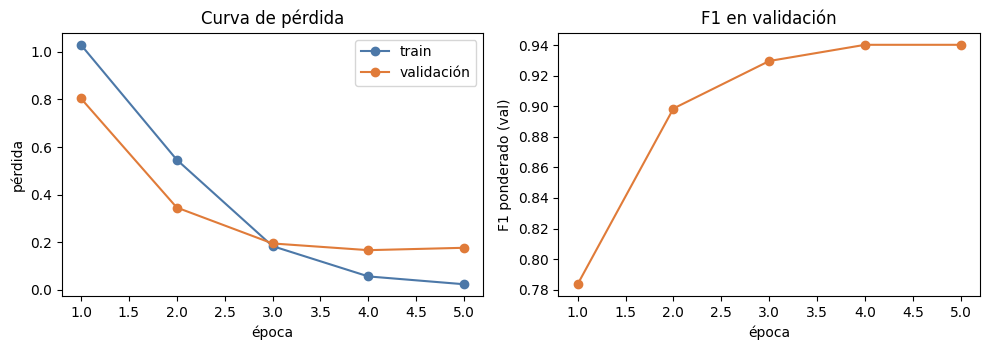

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(hist.epoca, hist.train_loss, marker="o", label="train", color="#4c78a8")
axs[0].plot(hist.epoca, hist.val_loss, marker="o", label="validación", color="#e07b39")
axs[0].set_xlabel("época"); axs[0].set_ylabel("pérdida"); axs[0].set_title("Curva de pérdida"); axs[0].legend()
axs[1].plot(hist.epoca, hist.val_f1, marker="o", color="#e07b39")
axs[1].set_xlabel("época"); axs[1].set_ylabel("F1 ponderado (val)"); axs[1].set_title("F1 en validación")
plt.tight_layout(); plt.savefig("results/figures/curvas_beto.png", dpi=150); plt.show()
hist.to_csv("results/tables/beto_historial_seed42.csv", index=False)

              precision    recall  f1-score   support

      Normal       0.96      1.00      0.98        46
 Riesgo Leve       1.00      0.91      0.95        32
 Riesgo Alto       0.92      0.96      0.94        24

    accuracy                           0.96       102
   macro avg       0.96      0.95      0.96       102
weighted avg       0.96      0.96      0.96       102



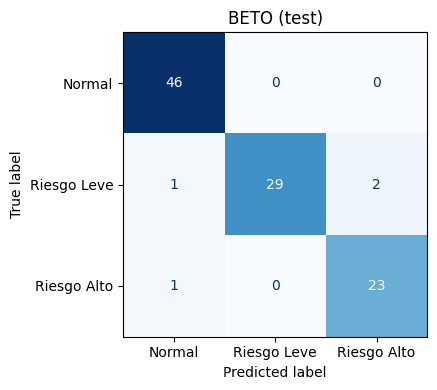

In [10]:
p_va, _ = predict(model, tok, X_va, cfg.max_len)
p_te, probs_te = predict(model, tok, X_te, cfg.max_len)
registrar("BETO", y_va, p_va, y_te, p_te)
print(report_text(y_te, p_te))
fig, ax = plt.subplots(figsize=(4.8, 4))
plot_confusion(y_te, p_te, "BETO (test)", ax)
plt.tight_layout(); plt.savefig("results/figures/cm_beto.png", dpi=150); plt.show()

### 3.1 Estabilidad entre semillas

Con pocos datos, el entrenamiento de BETO puede variar bastante según la semilla (inicialización de la cabeza y
orden de los lotes). Se repite con 2 semillas adicionales y se reporta media ± desviación estándar en *test*.

In [11]:
seed_rows = [{"seed": cfg.seed, **compute_metrics(y_te, p_te)}]
for s in (43, 44):
    c = BetoConfig(seed=s)
    m_s, t_s, _ = train_beto(train, val, c, verbose=False)
    p_s, _ = predict(m_s, t_s, X_te, c.max_len)
    seed_rows.append({"seed": s, **compute_metrics(y_te, p_s)})
    del m_s; torch.cuda.empty_cache()
seeds = pd.DataFrame(seed_rows); display(seeds.round(3))
resumen_seeds = seeds.drop(columns="seed").agg(["mean", "std"]).round(3); display(resumen_seeds)
seeds.to_csv("results/tables/beto_semillas.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

,seed,accuracy,f1_weighted,f1_macro,recall_clase0,recall_clase1,recall_clase2
0,42,0.961,0.961,0.956,1.0,0.906,0.958
1,43,0.990,0.990,0.988,1.0,1.000,0.958
2,44,0.990,0.990,0.991,1.0,0.969,1.000


,accuracy,f1_weighted,f1_macro,recall_clase0,recall_clase1,recall_clase2
mean,0.980,0.980,0.978,1.0,0.958,0.972
std,0.017,0.017,0.019,0.0,0.048,0.024


## 4. Comparación y latencia

In [12]:
lat = {}
lat["TF-IDF + LR"] = measure_latency(lambda t: tfidf_models["TF-IDF + LR"].predict([t])[0], list(X_te))
lat["Mayoritaria"] = measure_latency(lambda t: maj.predict([t])[0], list(X_te))
lat["BETO"] = measure_latency(make_predict_one(model, tok, cfg.max_len), list(X_te))
dev = str(get_device())

res = pd.DataFrame(rows)
test_res = res[res.split == "test"].set_index("modelo")
tabla = test_res[["f1_weighted", "f1_macro", "accuracy", "recall_clase2"]].copy()
tabla["latencia_media_ms"] = pd.Series({k: v["latencia_media_ms"] for k, v in lat.items()})
tabla["latencia_p95_ms"] = pd.Series({k: v["latencia_p95_ms"] for k, v in lat.items()})
tabla = tabla.loc[["Mayoritaria", "TF-IDF + LR", "TF-IDF + LR (balanceado)", "BETO"]].round(3)
print(f"Test | latencia de BETO medida en: {dev}")
display(tabla)
tabla.to_csv("results/tables/comparacion_test.csv")
res.to_csv("results/tables/resultados_val_test.csv", index=False)

Test | latencia de BETO medida en: cuda


,f1_weighted,f1_macro,accuracy,recall_clase2,latencia_media_ms,latencia_p95_ms
modelo,,,,,,
Mayoritaria,0.280,0.207,0.451,0.000,0.033,0.046
TF-IDF + LR,0.892,0.880,0.892,0.792,0.895,1.018
TF-IDF + LR (balanceado),0.893,0.877,0.892,0.792,NaN,NaN
BETO,0.961,0.956,0.961,0.958,9.517,12.003


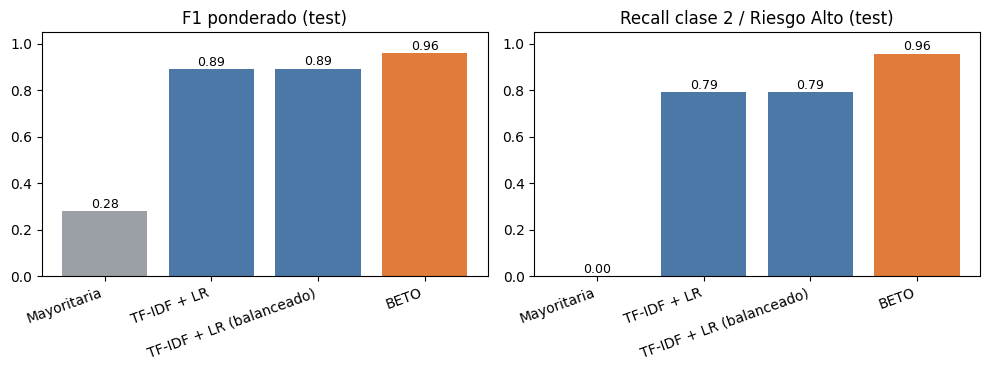

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
nombres = list(tabla.index)
colores = [COL["mayoritaria"], COL["tfidf"], COL["tfidf"], COL["beto"]]
for ax, met, tit in zip(axs, ["f1_weighted", "recall_clase2"], ["F1 ponderado (test)", "Recall clase 2 / Riesgo Alto (test)"]):
    ax.bar(range(len(nombres)), tabla[met], color=colores)
    ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres, rotation=20, ha="right")
    ax.set_ylim(0, 1.05); ax.set_title(tit)
    for i, v in enumerate(tabla[met]): ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("results/figures/comparacion_modelos.png", dpi=150); plt.show()

## 5. Análisis de errores

Interesa ver dónde BETO y TF-IDF fallan, sobre todo en frases con **negación** ("no presenta sangrado") y en
casos **ambiguos** o **mixtos** ("come bien pero cojea").

In [14]:
err = test[["texto", "etiqueta"]].copy()
err["pred_tfidf"] = preds["TF-IDF + LR"]; err["pred_beto"] = preds["BETO"]
neg = err.texto.str.contains(r"\b(?:no|ni|sin|nada|ningún|ninguna|descart\w+|ya no)\b", regex=True)
print(f"Subconjunto con negación: {neg.sum()} de {len(err)} observaciones de test")
for nombre, col in (("TF-IDF + LR", "pred_tfidf"), ("BETO", "pred_beto")):
    for etiqueta, sub in (("con negación", err[neg]), ("sin negación", err[~neg])):
        print(f"  {nombre:12s} accuracy {etiqueta}: {(sub[col] == sub.etiqueta).mean():.3f}  (n={len(sub)})")
print("\nErrores de BETO:")
display(err[err.pred_beto != err.etiqueta])
print("Errores de TF-IDF + LR:")
display(err[err.pred_tfidf != err.etiqueta])

Subconjunto con negación: 51 de 102 observaciones de test
  TF-IDF + LR  accuracy con negación: 0.882  (n=51)
  TF-IDF + LR  accuracy sin negación: 0.902  (n=51)
  BETO         accuracy con negación: 0.941  (n=51)
  BETO         accuracy sin negación: 0.980  (n=51)

Errores de BETO:


,texto,etiqueta,pred_tfidf,pred_beto
23,"no hay sangrado visible pero está pálido y frío, parece colapso",2,0,0
36,"tango descartamos convulsiones, todo tranquilo durante el turno eso sí, comió solo la mitad de su ración d...",1,1,0
60,"me da la impresión de que está triste, busca poco contacto",1,1,2
85,"quizá sea nada, pero hoy no respondió igual al llamado",1,0,2


Errores de TF-IDF + LR:


,texto,etiqueta,pred_tfidf,pred_beto
10,"empezó a perder pelo en la cola, sin picazón",1,0,1
19,"convulsión de mas de 5 minutos, no se recupera",2,1,2
23,"no hay sangrado visible pero está pálido y frío, parece colapso",2,0,0
26,panchita se negó a comer por tercer día consecutivo y pierde peso rápido registro realizado al finalizar l...,2,1,2
48,"se le cierran los ojos y se desploma, algo muy grave",2,1,2
52,panchita se negó a comer por tercer día consecutivo y pierde peso rápido duración: 30 min.,2,1,2
57,no tomó casi nada de agua en la mañana pero en la tarde sí,1,2,1
59,"se ve cansada pero fue el paseo largo, durmió y se recuperó",0,1,0
62,"ni una gota de sangre, la herida cerró perfecto",0,1,0
70,"se mueve más lento al levantarse, probablemente artrosis",1,2,1


## 6. Discusión preliminar (completar con los resultados de la ejecución)

Completar tras ejecutar, con evidencia de las tablas y figuras de arriba:

- **¿BETO supera al baseline?** ¿Por cuánto en F1 ponderado y en recall de la clase 2? ¿Es significativo frente a la
  variación entre semillas (§3.1)?
- **Sobreajuste:** ¿la pérdida de validación sube mientras la de entrenamiento baja (curvas)? ¿En qué época?
- **Desbalance:** ¿qué clase se confunde más (matrices de confusión)? ¿Mejora `class_weight="balanced"` en el baseline?
- **Negación y ambigüedad:** ¿qué modelo falla más en frases con negación o mixtas (§5)?
- **Estabilidad y cómputo:** desviación entre semillas, tiempo de entrenamiento y latencia (§4).
- **Limitaciones:** dataset sintético con frases de plantilla repetidas (posible optimismo) y test pequeño.